# Exercises 2.1 and 2.2: Trip production and attraction (4 points): Person A

Report chapters: `report/chapters/04_trip_production.tex` and `05_trip_attraction.tex`

**Sub-questions**

1. Ex 2.1: Total number of trips (1 point)
2. Ex 2.1: Trips per SPC and map of trips per IRIS (1 point)
3. Ex 2.2: Total N and arriving trips per municipality (2 points)
4. Ex 2.2: Scaling of O_i and hand-off file

**Reads**

- `data/processed/population_iris_14.parquet`: aggregated census RP2019 per IRIS (656 IRIS, from Ex. 1.2), $n_{i,s}$ =
  `C19_POP15P_CS1..8`
- `data/processed/iris.gpkg`, `data/processed/municipalities.gpkg` (IGN CONTOURS-IRIS 2021, from Ex. 1.1)
- `data/processed/employment_14.parquet` (from Ex. 1.3): working inhabitants, URSSAF employees, MOBPRO employed residents

**Writes**

- `data/processed/trips_production_14.parquet`: Ex. 2.1 per IRIS (`iris_id`, `municipality_id`, `O`, contribution per
  SPC `trips_cs1..8`, `offset`)
- `data/processed/trips_production_municipalities_14.parquet`: Ex. 2.1 per municipality (528 rows, sorted by
  `municipality_id`: `municipality_id`, `name`, `O`), input of Ex. 2.2
- `data/processed/ex21_results.json`: all numbers reported in Section 2.1 (unrounded)
- `data/processed/zones.parquet` (Ex. 2.2, HAND-OFF to Person B, contract in the setup cell)
- `report/figures/trips_per_spc.pdf`, `trips_per_iris_map.pdf` (Ex. 2.1), `arrivals_map.pdf` (Ex. 2.2), with `.png`
  previews

## Setup and configuration

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, LinearSegmentedColormap
from matplotlib.patches import ConnectionPatch, Rectangle
from shapely.geometry import box

# ---- Study area ------------------------------------------------------------------------
DEPARTMENT = "14"            # INSEE code of Calvados (region Normandie)
DEPARTMENT_NAME = "Calvados"
CRS = "EPSG:2154"            # RGF93 / Lambert-93, metres; all geometries and distances

# ---- Paths -----------------------------------------------------------------------------
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir() and (p / "report").is_dir())
DATA_RAW = ROOT / "data" / "raw"
DATA_PROCESSED = ROOT / "data" / "processed"
FIGURES_DIR = ROOT / "report" / "figures"

POPULATION_IRIS_PARQUET = DATA_PROCESSED / f"population_iris_{DEPARTMENT}.parquet"   # from ex12: aggregated census
                                                                                      # RP2019 per IRIS, n_{i,s}
IRIS_GPKG = DATA_PROCESSED / "iris.gpkg"                                      # from ex11 (656 IRIS)
MUNICIPALITIES_GPKG = DATA_PROCESSED / "municipalities.gpkg"                  # from ex11 (528 municipalities)
EMPLOYMENT_PARQUET = DATA_PROCESSED / f"employment_{DEPARTMENT}.parquet"      # from ex13 (municipality_id, name,
                                                                              # working_inhabitants, employees,
                                                                              # difference, employed_residents_mobpro, ...)
TRIPS_IRIS_PARQUET = DATA_PROCESSED / f"trips_production_{DEPARTMENT}.parquet"                       # Ex. 2.1 per IRIS
TRIPS_MUNICIPALITIES_PARQUET = DATA_PROCESSED / f"trips_production_municipalities_{DEPARTMENT}.parquet"  # Ex. 2.1 -> 2.2
RESULTS_21_JSON = DATA_PROCESSED / "ex21_results.json"
ZONES_PARQUET = DATA_PROCESSED / "zones.parquet"                              # HAND-OFF A -> B
ZONES_PLACEHOLDER_MARKER = DATA_PROCESSED / "zones.PLACEHOLDER"

# ---- Model parameters (assignment, Autumn 2026) -----------------------------------------
# Exercise 2.1, Table 1 of the assignment: O_i = max(beta_0 + sum_s beta_s * n_{i,s}, 0),
# n_{i,s} = population older than 15 years with SPC s in zone i. The offset beta_0 is added ONCE per zone.
TABLE_1 = pd.DataFrame(
    [
        (0, "Model offset", 27.244),
        (1, "Agriculteurs exploitants", 0.319),
        (2, "Artisans, commerçants et chefs d'entreprise", 0.994),
        (3, "Cadres et professions intellectuelles supérieures", 0.863),
        (4, "Professions intermédiaires", 0.990),
        (5, "Employés", 0.780),
        (6, "Ouvriers", 0.708),
        (7, "Retraités", 0.120),
        (8, "Autres personnes sans activité professionnelle", -0.073),
    ],
    columns=["s", "SPC", "beta"],
).set_index("s")
BETA_0 = float(TABLE_1.loc[0, "beta"])                        # model offset
BETA = TABLE_1.loc[1:8, "beta"]                               # growth factors beta_1 .. beta_8 (indexed by s)
SPC_LABELS = TABLE_1.loc[1:8, "SPC"].to_dict()                # same labels as in Ex. 1.2
SPC_COLUMNS = {s: f"C19_POP15P_CS{s}" for s in SPC_LABELS}    # n_{i,s} in the aggregated census
EXAMPLE_IRIS = "140980000"   # Thue et Mue (one IRIS = whole municipality): hand-computed check of the model

# Exercise 2.2: N = min(0.7 * sum_j W_j, 0.7 * sum_i O_i)
COMMUTER_SHARE = 0.7

# ---- Hand-off file zones.parquet (ex21_22 writes, ex23-ex32 read) --------------------------------
# One row per municipality: municipality_id (str, unique), name (str), geometry (EPSG:2154),
# O (float >= 0, scaled trips O'_i), D (float >= 0, arriving trips D_j), with O.sum() == D.sum() == N.
# The row order fixes the zone order of all vectors and matrices in Person B's part.
ZONE_COLUMNS = ["municipality_id", "name", "geometry", "O", "D"]


def validate_zones(zones, rtol=1e-9):
    # Raise ValueError if the hand-off contract is violated
    missing = [c for c in ZONE_COLUMNS if c not in zones.columns]
    if missing:
        raise ValueError(f"zones is missing columns: {missing}")
    if zones.crs is None or not zones.crs.equals(CRS):
        raise ValueError(f"zones must have CRS {CRS}, got {zones.crs}")
    if zones["municipality_id"].duplicated().any():
        raise ValueError("municipality_id must be unique")
    if zones[["O", "D"]].isna().any().any() or (zones[["O", "D"]] < 0).any().any():
        raise ValueError("O and D must be non-negative and not NaN")
    if not np.isclose(zones["O"].sum(), zones["D"].sum(), rtol=rtol, atol=0.0):
        raise ValueError(f"O.sum() != D.sum(): {zones['O'].sum()} vs {zones['D'].sum()} (both must equal N)")


def write_zones(zones, placeholder=False):
    # Validate and write zones.parquet; placeholder=True creates the marker file, a real write removes it
    validate_zones(zones)
    zones[ZONE_COLUMNS].to_parquet(ZONES_PARQUET)
    if placeholder:
        ZONES_PLACEHOLDER_MARKER.write_text(
            "zones.parquet contains PLACEHOLDER data (O = population 15+, D = URSSAF employment, "
            "scaled to the same total). Not the result of Exercises 2.1/2.2.\n"
        )
    else:
        ZONES_PLACEHOLDER_MARKER.unlink(missing_ok=True)

# ---- Figures ---------------------------------------------------------------------------
mpl.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 300, "font.size": 9, "axes.titlesize": 10,
    "axes.labelsize": 9, "legend.fontsize": 8, "pdf.fonttype": 42,
})
TEXT, TEXT_2, GRID = "#222222", "#666666", "#e6e6e6"
BLUE = "#257de0"                       # single series (SPC contributions)
REFERENCE = "#7a7a7a"                  # model offset (not an SPC)
SEQUENTIAL = LinearSegmentedColormap.from_list(   # one hue, light -> dark (as in Ex. 1.2)
    "blues", ["#cce3fd", "#9dc8f7", "#6aabf1", "#338ced", "#2370cd", "#1757ac", "#0e3d7e"])
SPC_SHORT = {   # short axis labels as in Ex. 1.2 (full names in the report table)
    1: "Agriculteurs exploitants", 2: "Artisans, commerçants,\nchefs d'entreprise",
    3: "Cadres, prof. intel. sup.", 4: "Professions intermédiaires", 5: "Employés", 6: "Ouvriers",
    7: "Retraités", 8: "Autres sans activité\nprofessionnelle",
}
TOWNS = {"14118": "Caen", "14047": "Bayeux", "14366": "Lisieux", "14762": "Vire Normandie"}  # as on the Ex. 1.1 map
CAEN_TOWNS = {"14118": "Caen", "14327": "Hérouville-\nSaint-Clair", "14437": "Mondeville", "14341": "Ifs"}  # zoom panel
TRIPS_CLASS_EDGES = [0, 100, 250, 500, 750, 1000, 1500, 2500, 4000]   # map classes (trips per IRIS)
CAEN_ZOOM_BUFFER_M = 3000    # zoom panel: bounding box of Caen + 3 km


def style_map_axes(ax):
    # Common map look: equal aspect, no axes frame or ticks
    ax.set_aspect("equal")
    ax.set_axis_off()
    return ax


def style_chart_axes(ax):
    # Recessive axes: no top/right spines, light grid behind the data
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(TEXT_2)
    ax.tick_params(colors=TEXT_2)
    ax.set_axisbelow(True)
    return ax


def scale_bar(ax, length_m, label, x_frac=0.06, y_frac=0.05):
    # Simple scale bar in map units (metres, Lambert-93)
    x0, x1 = ax.get_xlim()
    y0, y1 = ax.get_ylim()
    x = x0 + x_frac * (x1 - x0)
    y = y0 + y_frac * (y1 - y0)
    ax.plot([x, x + length_m], [y, y], color=TEXT, lw=1.5, solid_capstyle="butt")
    ax.text(x + length_m / 2, y + 0.015 * (y1 - y0), label, ha="center", va="bottom", fontsize=7, color=TEXT)


def save_figure(fig, name, preview_png=False):
    # Vector PDF for the report (report/figures/<name>.pdf, \includegraphics{<name>}), optional PNG preview
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    path = FIGURES_DIR / f"{name}.pdf"
    fig.savefig(path, format="pdf", bbox_inches="tight")
    if preview_png:
        fig.savefig(path.with_suffix(".png"), format="png", dpi=150, bbox_inches="tight")
    return path


def thousands(v, _=None):
    return f"{v:,.0f}"


TABLE_1

,SPC,beta
s,,
0,Model offset,27.244
1,Agriculteurs exploitants,0.319
2,"Artisans, commerçants et chefs d'entreprise",0.994
3,Cadres et professions intellectuelles supérieures,0.863
4,Professions intermédiaires,0.990
5,Employés,0.780
6,Ouvriers,0.708
7,Retraités,0.120
8,Autres personnes sans activité professionnelle,-0.073


## 1. Ex 2.1: Total number of trips (1 point)

### Data

The model needs the aggregated census **per IRIS**: `population_iris_14.parquet`, written by Ex. 1.2 from
"Population en 2019 – IRIS" (INSEE RP2019, `base-ic-evol-struct-pop-2019.CSV`, codes read as `str`). One row per IRIS
with `C19_POP15P_CS1..8` = $n_{i,s}$, the persons aged 15+ in SPC $s$ (weighted counts of the *exploitation
complémentaire*, not integers). Checks: the IRIS codes must be exactly those of the IGN polygons (`iris.gpkg`, Ex. 1.1),
every IRIS must belong to the same municipality in both files, and $\sum_s n_{i,s}$ = `C19_POP15P` in every IRIS.

In [2]:
df_iris = pd.read_parquet(POPULATION_IRIS_PARQUET)
n_columns = list(SPC_COLUMNS.values())
assert {"iris_id", "municipality_id", "P19_POP", "C19_POP15P", *n_columns} <= set(df_iris.columns)
df_iris = df_iris.sort_values("iris_id").reset_index(drop=True)
assert df_iris["iris_id"].is_unique

gdf_iris = gpd.read_file(IRIS_GPKG)
gdf_municipalities = gpd.read_file(MUNICIPALITIES_GPKG).sort_values("municipality_id").reset_index(drop=True)
assert gdf_iris.crs.equals(CRS) and gdf_municipalities.crs.equals(CRS)

# IRIS codes: aggregated census vs IGN polygons
census_codes, ign_codes = set(df_iris["iris_id"]), set(gdf_iris["iris_id"])
iris_only_census = sorted(census_codes - ign_codes)
iris_only_ign = sorted(ign_codes - census_codes)
print(f"IRIS: aggregated census {len(census_codes)} | IGN polygons {len(ign_codes)}")
print("  in the census, not in IGN:", iris_only_census)
print("  in IGN, not in the census:", iris_only_ign)
assert not iris_only_census and not iris_only_ign

df_codes = df_iris[["iris_id", "municipality_id"]].merge(gdf_iris[["iris_id", "municipality_id", "iris_type"]],
                                                         on="iris_id", suffixes=("", "_ign"), validate="1:1")
n_municipality_mismatch = int((df_codes["municipality_id"] != df_codes["municipality_id_ign"]).sum())
print("IRIS with a different municipality in census and IGN:", n_municipality_mismatch)
assert n_municipality_mismatch == 0
assert set(df_iris["municipality_id"]) == set(gdf_municipalities["municipality_id"]) and len(gdf_municipalities) == 528
df_iris = df_iris.merge(df_codes[["iris_id", "iris_type"]], on="iris_id", validate="1:1")

# Population 15+ = sum of the eight SPC in every IRIS
spc_gap = (df_iris[n_columns].sum(axis=1) - df_iris["C19_POP15P"]).abs().max()
print("max |sum of SPC 1-8 - C19_POP15P| per IRIS:", spc_gap)
assert spc_gap < 1e-6

n_iris_per_municipality = df_iris.groupby("municipality_id").size()
n_split = int((n_iris_per_municipality > 1).sum())
print(f"municipalities: {len(n_iris_per_municipality)} | split into IRIS: {n_split} "
      f"({int(n_iris_per_municipality[n_iris_per_municipality > 1].sum())} IRIS) | not split (1 IRIS): "
      f"{int((n_iris_per_municipality == 1).sum())}")
# IRIS types (IGN): Z = municipality not split, H = residential, A = activity zone, D = other (parks, port, ...)
df_iris_types = df_iris.groupby("iris_type").agg(
    n_iris=("iris_id", "size"), population=("P19_POP", "sum"), population_15p=("C19_POP15P", "sum"),
    min_population_15p=("C19_POP15P", "min"))
display(df_iris_types)
print("IRIS with population 15+ = 0:", int((df_iris["C19_POP15P"] == 0).sum()),
      "| < 50:", int((df_iris["C19_POP15P"] < 50).sum()),
      "| population 15+:", df_iris["C19_POP15P"].sum())

IRIS: aggregated census 656 | IGN polygons 656
  in the census, not in IGN: []
  in IGN, not in the census: []
IRIS with a different municipality in census and IGN: 0
max |sum of SPC 1-8 - C19_POP15P| per IRIS: 1.2732925824820995e-11
municipalities: 528 | split into IRIS: 17 (145 IRIS) | not split (1 IRIS): 511


,n_iris,population,population_15p,min_population_15p
iris_type,,,,
A,18,5526.862922,4947.803762,0.000000
D,4,2829.168581,2566.913314,19.887930
H,123,253570.968497,215688.907276,70.000000
Z,511,432978.000000,353030.599717,30.638298


IRIS with population 15+ = 0: 1 | < 50: 11 | population 15+: 576234.2240688053


### Model and decisions

$$O_i = \max\Big(\beta_0 + \sum_{s=1}^{8} \beta_s\, n_{i,s},\; 0\Big)$$

with the parameters of Table 1 (setup cell, `TABLE_1`). Three decisions:

1. **The offset is added once per zone.** In matrix form $O = \max(\beta_0 + X\beta, 0)$ with $X$ the
   $656 \times 8$ matrix of $n_{i,s}$: `BETA_0 + X @ beta`. The course notebook (*02 Trip generation*) computes
   `np.sum(intercept + X * coefficients, axis=1)`, which adds the intercept inside the sum over the eight SPC, i.e.
   **eight times** per zone. We do not copy that; the size of the error is printed below. The vectorised result is
   checked against a term-by-term computation for one zone (`EXAMPLE_IRIS`, Thue et Mue).
2. **Zone = IRIS.** The exercise asks for a map per IRIS, and the bonus part of the course notebook evaluates the model
   per IRIS. The model is therefore evaluated on the **656 IRIS** of Calvados (a municipality that is not split into
   IRIS is a single IRIS, type `Z`). The municipality value used in Ex. 2.2 and 2.3 is the sum over its IRIS,
   $O_{\text{municipality}} = \sum_{i \in \text{municipality}} O_i$. Because the offset is added once per zone, the
   total depends on the zoning: evaluating the model directly on the 528 municipalities gives
   $(656 - 528)\,\beta_0 = 128\,\beta_0$ trips less (plus or minus clipping effects). This variant is computed
   for comparison only.
3. **Clipping** with $\max(\cdot, 0)$ per zone. The offset is positive and only SPC 8 has a negative factor, so we
   expect no clipped zone; it is checked, not assumed.

In [3]:
X = df_iris[n_columns].to_numpy(dtype=float)     # n_{i,s}: one row per IRIS, columns s = 1..8
beta = BETA.to_numpy(dtype=float)                # beta_1 .. beta_8
O_linear = BETA_0 + X @ beta                     # offset added ONCE per zone
df_iris["O_linear"] = O_linear
df_iris["O"] = np.maximum(O_linear, 0.0)         # clipping per zone
clipped = O_linear < 0
n_clipped = int(clipped.sum())
clipped_trips = float(np.maximum(-O_linear, 0.0).sum())   # trips added by the clipping (0 if no zone is clipped)
O_total = df_iris["O"].sum()

print(f"total number of generated trips (656 IRIS): {O_total}")
print(f"clipped IRIS (beta_0 + sum_s beta_s n_is < 0): {n_clipped} | trips added by clipping: {clipped_trips}")
print(f"O per IRIS: min {df_iris['O'].min()} | median {df_iris['O'].median()} | max {df_iris['O'].max()}")
print(f"smallest linear value: {O_linear.min()} (IRIS {df_iris.loc[np.argmin(O_linear), 'iris_id']})")
print(f"IRIS with O_linear < beta_0 (net negative SPC part): {int((O_linear < BETA_0).sum())}")

total number of generated trips (656 IRIS): 291949.34678838344
clipped IRIS (beta_0 + sum_s beta_s n_is < 0): 0 | trips added by clipping: 0.0
O per IRIS: min 27.244 | median 258.13957363311584 | max 3642.2780697791245
smallest linear value: 27.244 (IRIS 141810103)
IRIS with O_linear < beta_0 (net negative SPC part): 0


In [4]:
# Hand-computed check for one zone: plain Python, term by term, independent of the matrix product
row = df_iris.set_index("iris_id").loc[EXAMPLE_IRIS]
terms = {s: float(TABLE_1.loc[s, "beta"]) * float(row[SPC_COLUMNS[s]]) for s in SPC_LABELS}
by_hand = BETA_0
for s in SPC_LABELS:
    by_hand += terms[s]
print(f"example IRIS {EXAMPLE_IRIS} ({gdf_municipalities.set_index('municipality_id').loc[row['municipality_id'], 'name']}):")
display(pd.DataFrame({"n_is": [float(row[SPC_COLUMNS[s]]) for s in SPC_LABELS],
                      "beta_s": [float(TABLE_1.loc[s, "beta"]) for s in SPC_LABELS],
                      "beta_s * n_is": list(terms.values())}, index=pd.Index(list(SPC_LABELS), name="s")))
print(f"beta_0 + sum_s beta_s n_is = {BETA_0} + {sum(terms.values())} = {by_hand}")
assert np.isclose(row["O"], by_hand, rtol=0.0, atol=1e-9)

# The course-notebook formula adds the offset once per SPC (8 times): 7 * beta_0 too much in every zone
O_course_formula = np.maximum(np.sum(BETA_0 + X * beta[np.newaxis, :], axis=1), 0.0)
i_example = int(np.flatnonzero(df_iris["iris_id"] == EXAMPLE_IRIS)[0])
assert np.isclose(O_course_formula[i_example], by_hand + 7 * BETA_0)
O_total_course_formula = O_course_formula.sum()
print(f"course-notebook formula (offset 8 times per zone): total {O_total_course_formula} "
      f"(+{O_total_course_formula - O_total} = 7 x {len(df_iris)} x beta_0, "
      f"{O_total_course_formula / O_total - 1:+.4%})")

example IRIS 140980000 (Thue et Mue):


,n_is,beta_s,beta_s * n_is
s,,,
1,42.945572,0.319,13.699637
2,173.693146,0.994,172.650987
3,464.397288,0.863,400.774859
4,985.982402,0.990,976.122578
5,1004.486761,0.780,783.499674
6,646.396776,0.708,457.648918
7,1014.170673,0.120,121.700481
8,484.101134,-0.073,-35.339383


beta_0 + sum_s beta_s n_is = 27.244 + 2890.7577508099876 = 2918.0017508099877
course-notebook formula (offset 8 times per zone): total 417053.7947883835 (+125104.44800000003 = 7 x 656 x beta_0, +42.8514%)


**Comparison: model evaluated directly on the 528 municipalities.** Same formula with
$n_{m,s} = \sum_{i \in m} n_{i,s}$. For comparison only; the IRIS-level result above is the one we use.

In [5]:
X_municipalities = df_iris.groupby("municipality_id")[n_columns].sum()
O_linear_municipalities = BETA_0 + X_municipalities.to_numpy(dtype=float) @ beta
O_municipalities_direct = np.maximum(O_linear_municipalities, 0.0)
n_clipped_municipalities = int((O_linear_municipalities < 0).sum())
O_total_municipalities_direct = O_municipalities_direct.sum()
n_extra_zones = len(df_iris) - len(X_municipalities)

print(f"IRIS level ({len(df_iris)} zones):          {O_total}")
print(f"municipality level ({len(X_municipalities)} zones):   {O_total_municipalities_direct} "
      f"(clipped municipalities: {n_clipped_municipalities})")
print(f"difference: {O_total - O_total_municipalities_direct} | {n_extra_zones} x beta_0 = {n_extra_zones * BETA_0} "
      f"| relative {O_total / O_total_municipalities_direct - 1:.4%}")
assert n_clipped == 0 and n_clipped_municipalities == 0
assert np.isclose(O_total - O_total_municipalities_direct, n_extra_zones * BETA_0)

# Municipality value used in Ex. 2.2 / 2.3: sum of the IRIS values
O_by_municipality = df_iris.groupby("municipality_id")["O"].sum()
assert np.isclose(O_by_municipality.sum(), O_total)
diff_per_municipality = O_by_municipality - pd.Series(O_municipalities_direct, index=X_municipalities.index)
print("per municipality, sum over IRIS - direct evaluation = (number of IRIS - 1) x beta_0:",
      bool(np.allclose(diff_per_municipality, (n_iris_per_municipality - 1) * BETA_0)))

IRIS level (656 zones):          291949.34678838344
municipality level (528 zones):   288462.1147883834 (clipped municipalities: 0)
difference: 3487.232000000018 | 128 x beta_0 = 3487.232 | relative 1.2089%
per municipality, sum over IRIS - direct evaluation = (number of IRIS - 1) x beta_0: True


**Result.** **Result.** The model generates **291,949 trips** in Calvados (291,949.3, evaluated on the 656 IRIS). **No IRIS is
clipped**: the smallest value is exactly $\beta_0$ = 27.244, in the only IRIS without population aged 15+ (the
activity zone of Cormelles-le-Royal), and no IRIS has a negative SPC part ($\sum_s \beta_s n_{i,s} \ge 0$ everywhere),
so $\max(\cdot, 0)$ is never active.

- Evaluated directly on the 528 municipalities, the model gives 288,462 trips: 3,487 = $128\,\beta_0$ less (−1.2 %).
  Per municipality the difference is exactly (number of IRIS − 1) $\times\,\beta_0$, so only the 17 municipalities split
  into IRIS (145 IRIS) are affected. We use the **IRIS-level** result: the exercise asks for the map per IRIS, and the
  municipality values of Ex. 2.2 are then sums of the mapped IRIS values with the same total.
- With the course-notebook formula (offset eight times per zone) the total would be 417,054 trips (+42.9 %).

## 2. Ex 2.1: Trips per SPC and map of trips per IRIS (1 point)

### Trips per SPC

Because the model is linear (and no zone is clipped), the total splits exactly into one contribution per SPC,
$T_s = \beta_s \sum_i n_{i,s} = \beta_s\, n_s$, plus the contribution of the offset, $\beta_0 \times 656$ zones, which
belongs to no SPC and is shown as a separate bar. $\beta_s$ is the number of trips per person aged 15+ of SPC $s$.
SPC 8 has a negative factor: each person in it *reduces* the trips of the zone, so its bar is negative.

In [6]:
n_s = df_iris[n_columns].sum().to_numpy(dtype=float)       # persons 15+ per SPC (department)
T_s = beta * n_s                                            # trips per SPC
offset_trips = BETA_0 * len(df_iris)                        # offset, once per IRIS
for s, c in SPC_COLUMNS.items():
    df_iris[f"trips_cs{s}"] = BETA[s] * df_iris[c]
df_iris["offset"] = BETA_0

df_spc_trips = pd.DataFrame({
    "SPC": list(SPC_LABELS.values()),
    "persons 15+ n_s": n_s,
    "trips per person beta_s": beta,
    "trips beta_s n_s": T_s,
    "share of total": T_s / O_total,
}, index=pd.Index(list(SPC_LABELS), name="s"))
df_spc_trips.loc[0] = ["Model offset (beta_0 x 656 IRIS)", np.nan, BETA_0, offset_trips, offset_trips / O_total]
df_spc_trips.loc["total"] = ["Total", n_s.sum(), np.nan, T_s.sum() + offset_trips, (T_s.sum() + offset_trips) / O_total]

bars_total = T_s.sum() + offset_trips
print(f"sum of the bars: {bars_total} | total O: {O_total} | difference (clipping): {O_total - bars_total}")
assert np.isclose(O_total, bars_total + clipped_trips)
print(f"trips of SPC 1-6: {T_s[:6].sum()} ({T_s[:6].sum() / O_total:.4%})")
print(f"average trips per person 15+ (all SPC, without offset): {T_s.sum() / n_s.sum()}")
with pd.option_context("display.float_format", "{:,.3f}".format):
    display(df_spc_trips)

sum of the bars: 291949.34678838344 | total O: 291949.34678838344 | difference (clipping): 0.0
trips of SPC 1-6: 259707.33894431614 (88.9563%)
average trips per person 15+ (all SPC, without offset): 0.4756352041243166


,SPC,persons 15+ n_s,trips per person beta_s,trips beta_s n_s,share of total
s,,,,,
1,Agriculteurs exploitants,"5,197.072",0.319,"1,657.866",0.006
2,"Artisans, commerçants et chefs d'entreprise","20,632.678",0.994,"20,508.882",0.070
3,Cadres et professions intellectuelles supérieures,"41,280.762",0.863,"35,625.298",0.122
4,Professions intermédiaires,"77,697.801",0.990,"76,920.823",0.263
5,Employés,"93,107.185",0.780,"72,623.604",0.249
6,Ouvriers,"73,970.148",0.708,"52,370.865",0.179
7,Retraités,"174,442.435",0.120,"20,933.092",0.072
8,Autres personnes sans activité professionnelle,"89,906.142",-0.073,"-6,563.148",-0.022
0,Model offset (beta_0 x 656 IRIS),NaN,27.244,"17,872.064",0.061


saved report\figures\trips_per_spc.pdf


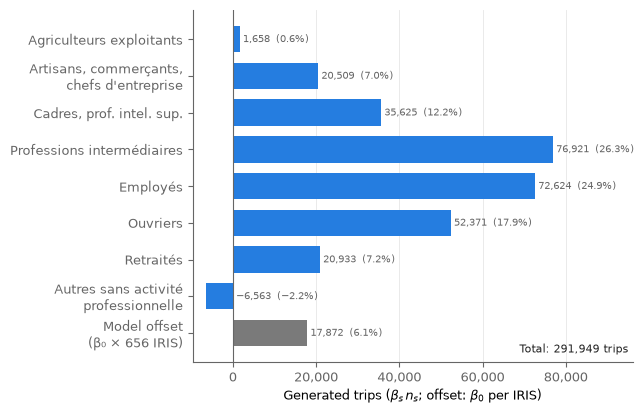

In [7]:
labels = [SPC_SHORT[s] for s in SPC_LABELS] + [f"Model offset\n(β₀ × {len(df_iris)} IRIS)"]
values = [*T_s, offset_trips]
colors = [BLUE] * len(T_s) + [REFERENCE]
y = np.arange(len(values))
y[-1] += 0.4      # small gap before the offset bar (not an SPC)

fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.barh(y, values, height=0.72, color=colors, linewidth=0)
x_max = max(values)
for yi, v in zip(y, values):
    label = f"{v:,.0f}  ({v / O_total:.1%})".replace("-", "−")   # typographic minus
    # negative bar (SPC 8): label right of the zero line, away from the axis labels
    ax.text(max(v, 0) + 0.01 * x_max, yi, label, fontsize=7, color=TEXT_2, va="center", ha="left")
ax.axvline(0, color=TEXT_2, lw=0.8)
ax.set_yticks(y, labels)
ax.invert_yaxis()
ax.set_xlim(min(values) - 0.04 * x_max, x_max * 1.25)
ax.set_xlabel(r"Generated trips ($\beta_s\,n_s$; offset: $\beta_0$ per IRIS)")
ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(thousands))
ax.xaxis.grid(True, color=GRID, lw=0.6)
ax.text(0.99, 0.02, f"Total: {O_total:,.0f} trips", transform=ax.transAxes, fontsize=8, color=TEXT,
        ha="right", va="bottom")
style_chart_axes(ax)
fig.tight_layout()
path = save_figure(fig, "trips_per_spc", preview_png=True)
print("saved", path.relative_to(ROOT))
plt.show()

**Reading.** Professions intermédiaires (76,921 trips, 26.3 %) and employés (72,624, 24.9 %) generate half of all trips,
followed by ouvriers (52,371, 17.9 %) and cadres (35,625, 12.2 %); SPC 1–6 together generate 259,707 trips (89.0 %).
Retirees are the largest group aged 15+ (174,442 persons) but generate only 20,933 trips ($\beta_7$ = 0.12 per person).
SPC 8 (89,906 persons: pupils, students, persons at home, unemployed who never worked) contributes **−6,563 trips**:
in the linear model each such person lowers the trips of the zone by 0.073. This is a correction term of the fitted
regression (the factors were estimated on commuting data, in which these persons hardly appear), not a negative number
of trips made by these persons; it never makes a zone negative here. The offset adds 17,872 trips (6.1 %). The bars
add up exactly to the total because no zone is clipped.

### Map of trips per IRIS

The 656 IRIS coloured by $O_i$ (classed sequential scale, `TRIPS_CLASS_EDGES`), with a second panel zoomed on Caen and
its first ring, where most IRIS are small. IRIS of type `Z` are whole municipalities (not split), so in rural areas
the map mostly reflects the population size of the municipality; split municipalities have IRIS of about 2,000
inhabitants each, hence similar values.

saved report\figures\trips_per_iris_map.pdf


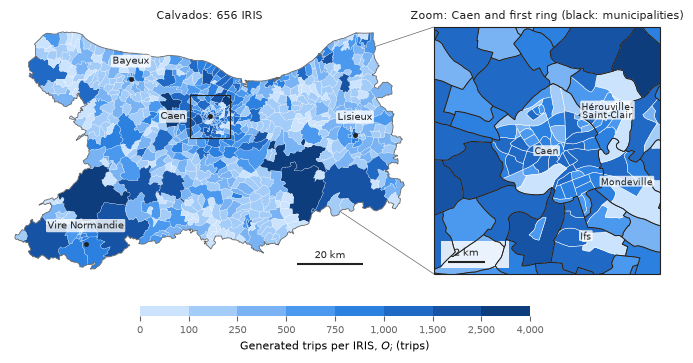

IRIS in the zoom panel: 100 | of them in Caen: 51
number of IRIS per class: {Interval(0, 100, closed='right'): 105, Interval(100, 250, closed='right'): 216, Interval(250, 500, closed='right'): 118, Interval(500, 750, closed='right'): 75, Interval(750, 1000, closed='right'): 67, Interval(1000, 1500, closed='right'): 57, Interval(1500, 2500, closed='right'): 13, Interval(2500, 4000, closed='right'): 5}


,iris_id,name,iris_name,iris_type,P19_POP,O
510,144310000,Mézidon Vallée d'Auge,Mézidon Vallée d'Auge,Z,9586.0,3642.278070
641,140610000,Souleuvre en Bocage,Souleuvre en Bocage,Z,8950.0,3507.748677
525,140980000,Thue et Mue,Thue et Mue,Z,6120.0,2918.001751
459,146540000,Saint-Pierre-en-Auge,Saint-Pierre-en-Auge,Z,7329.0,2642.174000
13,140760000,Blainville-sur-Orne,Blainville-sur-Orne,Z,5855.0,2516.210917


In [8]:
gdf_map = gdf_iris.merge(df_iris[["iris_id", "O", "P19_POP", "C19_POP15P"]], on="iris_id", validate="1:1")
assert len(gdf_map) == len(df_iris) and gdf_map["O"].notna().all()
assert TRIPS_CLASS_EDGES[0] <= gdf_map["O"].min() and gdf_map["O"].max() <= TRIPS_CLASS_EDGES[-1]
cmap = SEQUENTIAL.resampled(len(TRIPS_CLASS_EDGES) - 1)
norm = BoundaryNorm(TRIPS_CLASS_EDGES, cmap.N)
outline = gdf_municipalities.dissolve()
points = gdf_municipalities.set_index("municipality_id").geometry.representative_point()

caen = gdf_municipalities.set_index("municipality_id").loc[["14118"]]
zx0, zy0, zx1, zy1 = caen.total_bounds + np.array([-1, -1, 1, 1]) * CAEN_ZOOM_BUFFER_M

# Axes sized from the data extents so that both panels have the same height (inches)
dx0, dy0, dx1, dy1 = outline.total_bounds + np.array([-1, -1, 1, 1]) * 1500
r_dep, r_zoom = (dx1 - dx0) / (dy1 - dy0), (zx1 - zx0) / (zy1 - zy0)
W, gap, top, bottom = 6.5, 0.25, 0.3, 0.62
h = (W - gap) / (r_dep + r_zoom)
H = h + top + bottom
fig = plt.figure(figsize=(W, H))
ax = fig.add_axes([0, bottom / H, r_dep * h / W, h / H])
axz = fig.add_axes([(r_dep * h + gap) / W, bottom / H, r_zoom * h / W, h / H])
cax = fig.add_axes([0.2, 0.2 / H, 0.6, 0.1 / H])

# Department
gdf_map.plot(ax=ax, column="O", cmap=cmap, norm=norm, edgecolor="white", linewidth=0.15)
outline.boundary.plot(ax=ax, color=TEXT_2, linewidth=0.6)
ax.add_patch(Rectangle((zx0, zy0), zx1 - zx0, zy1 - zy0, fill=False, edgecolor=TEXT, lw=0.8, zorder=5))
for mid, name in TOWNS.items():
    p = points[mid]
    ax.plot(p.x, p.y, "o", color=TEXT, markersize=2.5, zorder=3)
    if mid == "14118":   # Caen: label left of the zoom rectangle
        x, y, ha, va = zx0 - 1500, p.y, "right", "center"
    else:
        x, y, ha, va = p.x, p.y + 4000, "center", "bottom"
    ax.text(x, y, name, fontsize=7, color=TEXT, ha=ha, va=va,
            bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.8), zorder=4)
style_map_axes(ax)
ax.set_xlim(dx0, dx1)
ax.set_ylim(dy0, dy1)
scale_bar(ax, 20_000, "20 km", x_frac=0.72, y_frac=0.04)

# Zoom on Caen and its first ring
gdf_map.plot(ax=axz, column="O", cmap=cmap, norm=norm, edgecolor="white", linewidth=0.35)
gdf_municipalities.boundary.plot(ax=axz, color=TEXT, linewidth=0.6)
for mid, name in CAEN_TOWNS.items():
    p = points[mid]
    axz.text(p.x, p.y, name, fontsize=6.5, color=TEXT, ha="center", va="center", linespacing=0.9,
             bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.8), zorder=4)
axz.set_xlim(zx0, zx1)
axz.set_ylim(zy0, zy1)
style_map_axes(axz)
axz.add_patch(Rectangle((0, 0), 1, 1, transform=axz.transAxes, fill=False, edgecolor=TEXT, lw=0.8, clip_on=False))
axz.add_patch(Rectangle((0.03, 0.025), 0.3, 0.11, transform=axz.transAxes, fc="white", ec="none", alpha=0.85,
                        zorder=1.5))   # below the bar, above the polygons
scale_bar(axz, 2_000, "2 km", x_frac=0.06, y_frac=0.05)
y_title = (bottom + h + 0.08) / H   # both panel titles on the same line
fig.text(r_dep * h / 2 / W, y_title, f"{DEPARTMENT_NAME}: {len(gdf_map)} IRIS", fontsize=8, color=TEXT, ha="center")
fig.text((r_dep * h + gap + r_zoom * h / 2) / W, y_title, "Zoom: Caen and first ring (black: municipalities)",
         fontsize=8, color=TEXT, ha="center")
for (xa, ya), (xb, yb) in [((zx1, zy1), (0, 1)), ((zx1, zy0), (0, 0))]:   # rectangle -> zoom panel
    fig.add_artist(ConnectionPatch(xyA=(xa, ya), coordsA=ax.transData, xyB=(xb, yb), coordsB=axz.transAxes,
                                   color=TEXT_2, lw=0.5, zorder=0))

sm = mpl.cm.ScalarMappable(cmap=cmap, norm=norm)
cbar = fig.colorbar(sm, cax=cax, orientation="horizontal", spacing="uniform", ticks=TRIPS_CLASS_EDGES)
cbar.ax.set_xticklabels([thousands(t) for t in TRIPS_CLASS_EDGES])
cbar.ax.tick_params(labelsize=7, colors=TEXT_2)
cbar.set_label("Generated trips per IRIS, $O_i$ (trips)", fontsize=8)
cbar.outline.set_visible(False)
path = save_figure(fig, "trips_per_iris_map", preview_png=True)
print("saved", path.relative_to(ROOT))
plt.show()

in_zoom = gdf_map.geometry.representative_point().within(box(zx0, zy0, zx1, zy1))
print(f"IRIS in the zoom panel: {int(in_zoom.sum())} | of them in Caen: "
      f"{int((in_zoom & (gdf_map['municipality_id'] == '14118')).sum())}")
print("number of IRIS per class:", pd.cut(gdf_map["O"], TRIPS_CLASS_EDGES).value_counts().sort_index().to_dict())
display(gdf_map.nlargest(5, "O")[["iris_id", "name", "iris_name", "iris_type", "P19_POP", "O"]])

**Reading.** Values range from 27 to 3,642 trips per IRIS (median 258). The darkest zones are large rural *communes
nouvelles* that form a single IRIS: Mézidon Vallée d'Auge (3,642), Souleuvre en Bocage (3,508), Thue et Mue (2,918),
Saint-Pierre-en-Auge (2,642), Blainville-sur-Orne (2,516). Outside the split municipalities the map therefore mostly
shows population size. The 123 residential IRIS (type `H`) of the 17 split municipalities have about 2,060 inhabitants
and 800 trips each on average, hence the even mid-range colours in Caen and its ring (zoom panel). The light IRIS
inside Caen are activity zones with few residents (types `A`/`D`: La Prairie, Mont Coco, the two Zones d'Activités) and
student quarters (Université, Pierre Heuze Sud: 65–69 % of the persons 15+ in SPC 8). Per municipality (sum over
IRIS), Caen generates 40,937 trips (14.0 %), followed by Hérouville-Saint-Clair (8,858), Lisieux (7,599), Vire
Normandie (6,285) and Bayeux (5,125).

### Plausibility check with real data

The model has no "true" value to compare with, but its coefficients were estimated in the course on Île-de-France
commuting data (outgoing commuters per municipality, MOBPRO), so $O_i$ should behave like commuting departures. Compare
$O$ per municipality (sum over IRIS) with two counts of Ex. 1.3 (`employment_14.parquet`): the **employed residents** of
MOBPRO RP2019 $R_i$ and the **working inhabitants** $W^{\text{res}}_i$ (persons 15+ in SPC 1–6). Department totals,
ratios, Pearson correlation per municipality (also without Caen, which dominates it), Spearman rank correlation, and
the ratio $O_i / R_i$ over the municipalities.

In [9]:
df_employment = pd.read_parquet(EMPLOYMENT_PARQUET).sort_values("municipality_id").reset_index(drop=True)
assert list(df_employment["municipality_id"]) == list(gdf_municipalities["municipality_id"])
df_check = df_employment[["municipality_id", "name", "employed_residents_mobpro", "working_inhabitants"]].copy()
df_check["O"] = df_check["municipality_id"].map(O_by_municipality)
df_check["population"] = df_check["municipality_id"].map(df_iris.groupby("municipality_id")["P19_POP"].sum())
assert df_check["O"].notna().all()

references = {"employed_residents_mobpro": "MOBPRO employed residents R", "working_inhabitants": "working inhabitants (SPC 1-6)"}
not_caen = df_check["municipality_id"] != "14118"
rows = {"O (model, IRIS level)": {"total": O_total}}
plausibility = {}
for col, label in references.items():
    total = df_check[col].sum()
    ratio = df_check["O"] / df_check[col]
    plausibility[col] = {
        "total": float(total),
        "ratio_O_to_reference": float(O_total / total),
        "pearson": float(df_check["O"].corr(df_check[col])),
        "pearson_without_caen": float(df_check.loc[not_caen, "O"].corr(df_check.loc[not_caen, col])),
        "spearman": float(df_check["O"].corr(df_check[col], method="spearman")),
        "ratio_per_municipality_median": float(ratio.median()),
        "ratio_per_municipality_p05": float(ratio.quantile(0.05)),
        "ratio_per_municipality_p95": float(ratio.quantile(0.95)),
    }
    rows[label] = plausibility[col]
display(pd.DataFrame(rows).T)

# Where the ratio O / R deviates: small municipalities get the offset regardless of their size
df_check["ratio_O_R"] = df_check["O"] / df_check["employed_residents_mobpro"]
df_check["size_class"] = pd.cut(df_check["population"], [0, 200, 500, 1000, 2000, 5000, np.inf],
                                labels=["< 200", "200-500", "500-1,000", "1,000-2,000", "2,000-5,000", "> 5,000"])
df_ratio_by_size = df_check.groupby("size_class", observed=True).agg(
    municipalities=("O", "size"), O=("O", "sum"), employed_residents=("employed_residents_mobpro", "sum"),
    median_ratio=("ratio_O_R", "median"))
df_ratio_by_size["ratio_of_sums"] = df_ratio_by_size["O"] / df_ratio_by_size["employed_residents"]
display(df_ratio_by_size)
caen_check = df_check.set_index("municipality_id").loc["14118"]
print(f"Caen: O {caen_check['O']} | R {caen_check['employed_residents_mobpro']} | ratio {caen_check['ratio_O_R']}")

,total,ratio_O_to_reference,pearson,pearson_without_caen,spearman,ratio_per_municipality_median,ratio_per_municipality_p05,ratio_per_municipality_p95
"O (model, IRIS level)",291949.346788,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MOBPRO employed residents R,277130.986523,1.053471,0.999509,0.997411,0.997098,1.109808,0.962576,1.620353
working inhabitants (SPC 1-6),311885.647778,0.936078,0.999845,0.999148,0.998521,1.014225,0.886897,1.453486


,municipalities,O,employed_residents,median_ratio,ratio_of_sums
size_class,,,,,
< 200,118,9810.994876,7251.875594,1.373078,1.352891
200-500,169,26848.046137,23288.251438,1.152548,1.152858
"500-1,000",103,32674.197228,31416.018528,1.040255,1.040049
"1,000-2,000",63,40198.498564,39534.377909,1.012477,1.016799
"2,000-5,000",55,68350.227504,66858.804276,1.017842,1.022307
"> 5,000",20,114067.382481,108781.658777,1.049693,1.048590


Caen: O 40937.35282807607 | R 38626.62400901483 | ratio 1.0598221790887539


**Reading.** The model generates 291,949 trips against 277,131 MOBPRO employed residents (ratio **1.05**) and 311,886
working inhabitants (ratio 0.94). Per municipality, $O_i$ and $R_i$ correlate at **0.9995** (0.9974 without Caen;
Spearman 0.997). The model thus produces about **one trip per employed resident**: it behaves like the number of
home-to-work departures of the employed residents (MOBPRO includes the 30 % who work in their own municipality),
which is consistent with coefficients estimated on commuting data. The ratio $O_i/R_i$ has median 1.11 (5–95 %:
0.96–1.62). It is close to 1 for municipalities above 500 inhabitants (1.02–1.05 by size class; Caen 1.06) and higher
for small ones (1.35 below 200 inhabitants), because the offset of 27.2 trips per zone is large compared with a few
dozen employed residents.

### Results of Ex. 2.1 (input of Ex. 2.2, numbers for the report)

- `trips_production_14.parquet`: one row per IRIS (`iris_id`, `municipality_id`, `O`, `trips_cs1..8` =
  $\beta_s n_{i,s}$, `offset` = $\beta_0$); `O` = $\max$(offset + contributions, 0).
- `trips_production_municipalities_14.parquet`: 528 municipalities sorted by `municipality_id` (`municipality_id`,
  `name`, `O` = sum over the IRIS). This is the $O_i$ of Ex. 2.2 and 2.3.
- `ex21_results.json`: all reported numbers, unrounded.

In [10]:
trip_columns = [f"trips_cs{s}" for s in SPC_LABELS]
df_trips_iris = df_iris[["iris_id", "municipality_id", "O", *trip_columns, "offset"]].copy()
assert np.allclose(df_trips_iris["O"], np.maximum(df_trips_iris[[*trip_columns, "offset"]].sum(axis=1), 0.0))
df_trips_iris.to_parquet(TRIPS_IRIS_PARQUET)
print("saved", TRIPS_IRIS_PARQUET.relative_to(ROOT), df_trips_iris.shape)

df_trips_municipalities = gdf_municipalities[["municipality_id", "name"]].copy()
df_trips_municipalities["O"] = df_trips_municipalities["municipality_id"].map(O_by_municipality)
df_trips_municipalities = df_trips_municipalities.sort_values("municipality_id").reset_index(drop=True)
assert len(df_trips_municipalities) == 528 and df_trips_municipalities["municipality_id"].is_unique
assert df_trips_municipalities["O"].notna().all() and np.isclose(df_trips_municipalities["O"].sum(), O_total)
df_trips_municipalities = pd.DataFrame(df_trips_municipalities)   # plain table, no geometry
df_trips_municipalities.to_parquet(TRIPS_MUNICIPALITIES_PARQUET)
print("saved", TRIPS_MUNICIPALITIES_PARQUET.relative_to(ROOT), df_trips_municipalities.shape)


def records(df, columns):
    return {str(r["municipality_id"] if "municipality_id" in r else r.name): {
        c: (r[c].item() if hasattr(r[c], "item") else r[c]) for c in columns} for _, r in df.iterrows()}


top_iris = gdf_map.nlargest(5, "O")
results_21 = {
    "model": {
        "formula": "O_i = max(beta_0 + sum_s beta_s * n_is, 0), offset added once per zone",
        "beta_0": BETA_0,
        "beta": {str(s): float(v) for s, v in BETA.items()},
        "zone": "IRIS (656); municipality O = sum over its IRIS",
        "example_iris": EXAMPLE_IRIS,
        "example_iris_O": float(by_hand),
    },
    "data": {
        "n_iris": int(len(df_iris)),
        "n_municipalities": int(len(n_iris_per_municipality)),
        "n_municipalities_split": n_split,
        "n_iris_in_split_municipalities": int(n_iris_per_municipality[n_iris_per_municipality > 1].sum()),
        "iris_types": {k: int(v) for k, v in df_iris_types["n_iris"].items()},
        "iris_only_in_census": iris_only_census,
        "iris_only_in_ign": iris_only_ign,
        "n_iris_municipality_mismatch": n_municipality_mismatch,
        "max_abs_spc_sum_gap": float(spc_gap),
        "population_15p": float(df_iris["C19_POP15P"].sum()),
        "n_iris_population_15p_zero": int((df_iris["C19_POP15P"] == 0).sum()),
        "n_iris_population_15p_below_50": int((df_iris["C19_POP15P"] < 50).sum()),
    },
    "total": {
        "O_iris_level": float(O_total),
        "O_municipality_level_direct": float(O_total_municipalities_direct),
        "difference_iris_minus_municipality": float(O_total - O_total_municipalities_direct),
        "n_extra_zones": int(n_extra_zones),
        "relative_difference": float(O_total / O_total_municipalities_direct - 1),
        "O_course_notebook_formula": float(O_total_course_formula),
        "course_formula_relative_error": float(O_total_course_formula / O_total - 1),
        "n_clipped_iris": n_clipped,
        "n_clipped_municipalities_direct": n_clipped_municipalities,
        "clipped_trips": clipped_trips,
        "min_O_linear_iris": float(O_linear.min()),
    },
    "per_iris": {
        "min": float(df_iris["O"].min()), "median": float(df_iris["O"].median()),
        "mean": float(df_iris["O"].mean()), "max": float(df_iris["O"].max()),
        "class_edges": TRIPS_CLASS_EDGES,
        "n_per_class": {str(k): int(v) for k, v in pd.cut(gdf_map["O"], TRIPS_CLASS_EDGES).value_counts().sort_index().items()},
        "top5": {r["iris_id"]: {"name": r["name"], "iris_name": r["iris_name"], "iris_type": r["iris_type"],
                                "P19_POP": float(r["P19_POP"]), "O": float(r["O"])} for _, r in top_iris.iterrows()},
        "by_type_O": {k: float(v) for k, v in df_iris.groupby("iris_type")["O"].sum().items()},
    },
    "per_spc": {
        str(s): {"SPC": SPC_LABELS[s], "n_s": float(n_s[k]), "beta_s": float(beta[k]), "trips": float(T_s[k]),
                 "share": float(T_s[k] / O_total)} for k, s in enumerate(SPC_LABELS)},
    "offset": {"n_zones": int(len(df_iris)), "trips": float(offset_trips), "share": float(offset_trips / O_total)},
    "bars_sum": float(bars_total),
    "trips_spc_1_6": float(T_s[:6].sum()),
    "trips_per_person_15p_without_offset": float(T_s.sum() / n_s.sum()),
    "plausibility": {
        "O_iris_level": float(O_total),
        **plausibility,
        "ratio_by_size_class": {str(k): {c: float(v) for c, v in r.items()} for k, r in df_ratio_by_size.iterrows()},
        "caen": {"O": float(caen_check["O"]), "employed_residents_mobpro": float(caen_check["employed_residents_mobpro"]),
                 "ratio": float(caen_check["ratio_O_R"])},
    },
    "municipalities_top5": records(df_trips_municipalities.nlargest(5, "O"), ["name", "O"]),
}
RESULTS_21_JSON.write_text(json.dumps(results_21, indent=2, ensure_ascii=False), encoding="utf-8")
print("saved", RESULTS_21_JSON.relative_to(ROOT))
results_21["total"]

saved data\processed\trips_production_14.parquet (656, 12)
saved data\processed\trips_production_municipalities_14.parquet (528, 3)
saved data\processed\ex21_results.json


{'O_iris_level': 291949.34678838344,
 'O_municipality_level_direct': 288462.1147883834,
 'difference_iris_minus_municipality': 3487.232000000018,
 'n_extra_zones': 128,
 'relative_difference': 0.012089046780227042,
 'O_course_notebook_formula': 417053.7947883835,
 'course_formula_relative_error': 0.42851422473187006,
 'n_clipped_iris': 0,
 'n_clipped_municipalities_direct': 0,
 'clipped_trips': 0.0,
 'min_O_linear_iris': 27.244}

## 3. Ex 2.2: Total N and arriving trips per municipality (2 points)

`N = min(0.7 * sum_j W_j, 0.7 * sum_i O_i)`, `D_j = W_j / sum W * N`. Report N and map the arriving trips per municipality. Figure: `arrivals_map`.

In [11]:
# TODO

## 4. Ex 2.2: Scaling of O_i and hand-off file

Scale `O'_i = N * O_i / sum O` so that `O.sum() == D.sum() == N`, build the municipality `GeoDataFrame` with columns `municipality_id, name, geometry, O, D` and write it with `write_zones(zones)` (setup cell), which validates the contract and removes the placeholder marker.

In [12]:
# TODO

## Problems encountered

### Ex. 2.1

- **Census per IRIS.** `population_14.parquet` (Ex. 1.2) is per municipality. Ex. 1.2 now also writes
  `population_iris_14.parquet` (656 IRIS, codes as `str`); it was re-run from a fresh kernel and `ex12_results.json` is
  unchanged. The IRIS codes match the IGN polygons exactly (0 mismatches, same municipality for every IRIS), and
  $\sum_s n_{i,s}$ = `C19_POP15P` in every IRIS.
- **Offset in the course notebook.** `np.sum(intercept + X * coefficients, axis=1)` adds the intercept once per SPC
  (8 times per zone). For Calvados this would give 417,054 trips instead of 291,949 (+42.9 %). We use
  `BETA_0 + X @ beta` and check it term by term on one zone.
- **Total depends on the zoning.** Because the offset is added once per zone, IRIS give 3,487 = $128\,\beta_0$ trips
  more than municipalities (1.2 %). We evaluate per IRIS (map per IRIS, as in the bonus of the course notebook) and sum
  the IRIS to municipalities.
- **Offset in (almost) empty zones.** The offset creates trips where nobody lives: the activity zone of
  Cormelles-le-Royal has no population aged 15+ and still gets 27.2 trips; the 11 IRIS with fewer than 50 persons 15+
  get 498 trips. Small municipalities get relatively more trips (ratio to employed residents 1.35 below 200
  inhabitants). Kept as specified by the model; the offset is 6.1 % of the total.
- **Negative factor of SPC 8.** Clipping is never needed in Calvados, but the decomposition per SPC has a negative bar
  (−6,563 trips), explained as a regression correction term.
- **Transfer of the coefficients.** The factors come from the course model estimated on Île-de-France; applied to
  Calvados they give about one trip per employed resident (ratio 1.05 to MOBPRO, correlation 0.9995), so the level is
  plausible.

### Ex. 2.2

TODO: note every problem and how it was solved (partial points are given for documented problems); copy it into the
`\paragraph{Problems encountered.}` of the report chapter.